# Análisis Exploratorio — Tema 3: Centralidad y clientes clave en la red

Hito 1 : Redes Complejas. Este notebook contiene solo la estructura y las guías de cada paso; el desarrollo lo completa el equipo.

## 1. Configuración e importación de librerías

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from networkx.algorithms import bipartite

pd.set_option("display.max_columns", None)


## 2. Carga de datos

In [2]:
# El archivo contiene una hoja resumen y una hoja con los registros crudos.
archivo = "datosRed.xlsx"
df = pd.read_excel(archivo, sheet_name="Anonimizado")

display(df.head(10))


,AÑO,PERSONA,TIPO DE SERVICIO,NOMBRE DE LA TAREA,MODALIDAD,COMPLEJIDAD
0,2019,ID_1,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
1,2019,ID_2,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
2,2019,ID_3,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
3,2019,ID_4,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
4,2019,ID_5,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
5,2019,ID_6,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
6,2019,ID_7,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
7,2019,ID_8,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
8,2019,ID_9,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
9,2019,ID_10,SERV_1,TAREA_1.1,PRESENCIAL,BAJA



INTERPRETACIÓN:
Se cargaron 10,384 registros y 6 variables desde la hoja Anonimizado. Cada fila representa una relación registrada entre una persona y un servicio.

## 3. Reconocimiento inicial de los datos

In [3]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Dimensiones:", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos por columna:")
print(df.isnull().sum())

print("\nClientes únicos:", df["PERSONA"].nunique())
print("Servicios únicos:", df["TIPO DE SERVICIO"].nunique())
print("Años cubiertos:", df["AÑO"].nunique())
print("Rango de años:", df["AÑO"].min(), "-", df["AÑO"].max())
print("Duplicados exactos:", df.duplicated().sum())



Filas: 10384
Columnas: 6
Dimensiones: (10384, 6)

Tipos de datos:
AÑO                    int64
PERSONA               object
TIPO DE SERVICIO      object
NOMBRE DE LA TAREA    object
MODALIDAD             object
COMPLEJIDAD           object
dtype: object

Valores nulos por columna:
AÑO                   0
PERSONA               0
TIPO DE SERVICIO      0
NOMBRE DE LA TAREA    0
MODALIDAD             0
COMPLEJIDAD           0
dtype: int64

Clientes únicos: 5090
Servicios únicos: 7
Años cubiertos: 6
Rango de años: 2019 - 2024
Duplicados exactos: 2429


INTERPRETACIÓN:
El conjunto contiene 10,384 filas y 6 columnas. La revisión de tipos, nulos, duplicados y categorías permite comprobar la calidad de los datos antes de construir la red.

## 4. Limpieza de datos

In [4]:
# Trabajamos sobre una copia para conservar intacto el DataFrame original.
df_limpio = df.copy()

# Normalizar columnas de texto.
columnas_texto = ["PERSONA", "TIPO DE SERVICIO", "NOMBRE DE LA TAREA", "MODALIDAD", "COMPLEJIDAD"]
for columna in columnas_texto:
    df_limpio[columna] = (
        df_limpio[columna]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# No hay valores faltantes en este dataset. Si aparecieran, se excluyen de los campos
# indispensables para construir la red cliente-servicio.
df_limpio = df_limpio.dropna(subset=["PERSONA", "TIPO DE SERVICIO"])

# Eliminar registros exactamente duplicados para no contar dos veces la misma observación.
duplicados = df_limpio.duplicated().sum()
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

print("Duplicados eliminados:", duplicados)
print("Dimensiones originales:", df.shape)
print("Dimensiones después de limpieza:", df_limpio.shape)
display(df_limpio.head())



Duplicados eliminados: 2429
Dimensiones originales: (10384, 6)
Dimensiones después de limpieza: (7955, 6)


,AÑO,PERSONA,TIPO DE SERVICIO,NOMBRE DE LA TAREA,MODALIDAD,COMPLEJIDAD
0,2019,ID_1,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
1,2019,ID_2,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
2,2019,ID_3,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
3,2019,ID_4,SERV_1,TAREA_1.1,PRESENCIAL,BAJA
4,2019,ID_5,SERV_1,TAREA_1.1,PRESENCIAL,BAJA


INTERPRETACIÓN:
Después de la limpieza quedan 7,955 registros. Se normalizaron los textos y se eliminaron duplicados exactos para evitar que una misma relación cliente-servicio se contabilice artificialmente más de una vez.

## 4.1 Diagnóstico de densidad (antes de construir la red)

Antes de proyectar la red cliente-cliente, revisamos cómo se distribuyen los clientes entre los tipos de servicio, ya que con pocas categorías y muchos clientes por categoría la proyección puede volverse artificialmente densa.

In [5]:
conteo_servicios = df_limpio["TIPO DE SERVICIO"].value_counts()
print("Clientes únicos por servicio:")
print(conteo_servicios)

print("\nServicios que agrupan al menos al 20% de los clientes:")
umbral = 0.20 * df_limpio["PERSONA"].nunique()
for servicio in conteo_servicios.index:
    clientes_servicio = df_limpio[df_limpio["TIPO DE SERVICIO"] == servicio]["PERSONA"].nunique()
    if clientes_servicio >= umbral:
        print(f"  {servicio}: {clientes_servicio} clientes únicos "
              f"({clientes_servicio / df_limpio['PERSONA'].nunique():.1%} del total)")


Clientes únicos por servicio:
TIPO DE SERVICIO
SERV_2    3441
SERV_1    3260
SERV_4     681
SERV_5     295
SERV_6     119
SERV_7     111
SERV_3      48
Name: count, dtype: Int64

Servicios que agrupan al menos al 20% de los clientes:
  SERV_2: 2957 clientes únicos (58.1% del total)
  SERV_1: 2412 clientes únicos (47.4% del total)


INTERPRETACIÓN:
SERV_2 es usado por el 58.1% de los clientes y SERV_1 por el 47.4%. Con solo dos servicios se concentran a la mayoría de los clientes del dataset, frente a los otros 5 servicios que son mucho mas especificos . Ademas, con solo 7 tipos de servicio en total, cualquier servicio con muchos clientes genera Grupo totalmente conectado , lo cual puede inflar artificialmente la densidad de la red proyectada. Esto se confirma mas abajo, despues de construir la proyeccion.

## 5. Construcción de la red bipartita cliente–servicio

In [7]:
# Crear la red bipartita cliente-servicio.
B = nx.Graph()

clientes = df_limpio["PERSONA"].unique().tolist()
servicios = df_limpio["TIPO DE SERVICIO"].unique().tolist()

B.add_nodes_from(clientes, bipartite="cliente")
B.add_nodes_from(servicios, bipartite="servicio")

# En un grafo simple basta una arista por cada par cliente-servicio.
relaciones = df_limpio[["PERSONA", "TIPO DE SERVICIO"]].drop_duplicates()
B.add_edges_from(relaciones.itertuples(index=False, name=None))

print("Clientes:", len(clientes))
print("Servicios:", len(servicios))
print("Nodos totales:", B.number_of_nodes())
print("Enlaces cliente-servicio:", B.number_of_edges())



Clientes: 5090
Servicios: 7
Nodos totales: 5097
Enlaces cliente-servicio: 6301


INTERPRETACIÓN:
La red bipartita contiene 5,097 nodos y 6,301 enlaces. Los nodos se dividen en clientes y servicios; un enlace indica que un cliente está asociado con un servicio.

## 6. Proyección a red cliente–cliente

In [8]:
# Proyectar la red bipartita sobre los clientes.
# El peso representa cuántos servicios comparten dos clientes.
G_clientes = bipartite.weighted_projected_graph(B, clientes)

print("Nodos de la red cliente-cliente:", G_clientes.number_of_nodes())
print("Enlaces de la red cliente-cliente:", G_clientes.number_of_edges())

# Mostrar algunos enlaces y sus pesos.
print("\nEjemplos de relaciones:")
for u, v, datos in list(G_clientes.edges(data=True))[:10]:
    print(u, "-", v, "| servicios compartidos:", datos["weight"])



Nodos de la red cliente-cliente: 5090
Enlaces de la red cliente-cliente: 7189307

Ejemplos de relaciones:
ID_1 - ID_3114 | servicios compartidos: 1
ID_1 - ID_408 | servicios compartidos: 1
ID_1 - ID_3611 | servicios compartidos: 1
ID_1 - ID_1609 | servicios compartidos: 1
ID_1 - ID_1406 | servicios compartidos: 1
ID_1 - ID_4204 | servicios compartidos: 1
ID_1 - ID_4791 | servicios compartidos: 1
ID_1 - ID_4666 | servicios compartidos: 1
ID_1 - ID_1769 | servicios compartidos: 1
ID_1 - ID_245 | servicios compartidos: 1


INTERPRETACIÓN:
La proyección cliente-cliente contiene 5,090 clientes y 7,189,307 conexiones. Dos clientes quedan conectados cuando comparten al menos un servicio, y el peso del enlace indica cuántos servicios tienen en común.

### 6.1 Filtrado de la red por peso mínimo (hallazgo de densidad)

La proyección sin filtrar resulto en una densidad de 55.5% con 7,189,307 enlaces entre 5,090 clientes. Se probo excluir los servicios más comunes (SERV_1, SERV_2), pero la densidad se mantuvo igual de alta con 56.7%. Esto demuestra que el problema no es un servicio puntual, sino la naturaleza de la proyeccion bipartita con pocas categorias de servicio.

En vez de eso, se analiza cuantos servicios tienen en comun cada par de clientes, para decidir a partir de que numero de servicios compartidos una conexion realmente vale la pena conservar.

In [9]:
from collections import Counter

pesos = [d["weight"] for _, _, d in G_clientes.edges(data=True)]
print("Distribución de pesos (num. servicios compartidos):")
print(Counter(pesos))

# 1,2 o 3 relaciones, es decir, 2 clientes usaron 1,2 o 3 servicios iguales 
for umbral in [1, 2, 3]:
    n = sum(1 for p in pesos if p >= umbral)
    print(f"Enlaces con peso >= {umbral}: {n:,} ({n/len(pesos):.1%} del total)")

# Filtrar la red reteniendo solo enlaces con al menos 2 servicios compartidos
G_clientes_filtrado = nx.Graph(
    (u, v, d) for u, v, d in G_clientes.edges(data=True) if d["weight"] >= 2
)
print("\nRed filtrada (peso >= 2):")
print("Nodos:", G_clientes_filtrado.number_of_nodes())
print("Enlaces:", G_clientes_filtrado.number_of_edges())
print(f"Densidad: {nx.density(G_clientes_filtrado):.4f}")


Distribución de pesos (num. servicios compartidos):
Counter({1: 6967818, 2: 207297, 3: 11928, 4: 2198, 5: 66})
Enlaces con peso >= 1: 7,189,307 (100.0% del total)
Enlaces con peso >= 2: 221,489 (3.1% del total)
Enlaces con peso >= 3: 14,192 (0.2% del total)

Red filtrada (peso >= 2):
Nodos: 863
Enlaces: 221489
Densidad: 0.5955


INTERPRETACIÓN:
El 97% de los enlaces de la proyección original correspondían a pares de clientes que comparten exactamente un servicio (peso = 1), lo cual aporta poca información dado que con solo 7 servicios esa coincidencia es casi aleatoria. Aplicando un umbral de peso ≥ 2 (compartir al menos 2 servicios), la red se reduce a 221,489 enlaces — un tamaño manejable para calcular centralidades como intermediación, y cada conexión refleja una relación más significativa entre clientes. **A partir de aquí, el análisis exploratorio y el cálculo de centralidades se realizan sobre `G_clientes_filtrado`, no sobre `G_clientes`.**

## 7. Guardado de la red

In [10]:
# Guardar la red filtrada (peso >= 2) para reutilizarla sin reconstruirla.
nx.write_graphml(G_clientes_filtrado, "red_clientes_filtrada.graphml")
print("Red guardada como: red_clientes_filtrada.graphml")


Red guardada como: red_clientes_filtrada.graphml


INTERPRETACIÓN:
La red proyectada fue guardada en formato GraphML. Esto permite reutilizarla en los análisis posteriores sin volver a ejecutar todo el proceso de construcción y proyección.

## 8. Análisis exploratorio de la red

### 8.1 Métricas globales

In [11]:
n_nodos = G_clientes_filtrado.number_of_nodes()
n_enlaces = G_clientes_filtrado.number_of_edges()
densidad = nx.density(G_clientes_filtrado)

# Calcular grados
grados = dict(G_clientes_filtrado.degree())
grados_ponderados = dict(G_clientes_filtrado.degree(weight='weight'))

grado_promedio = np.mean(list(grados.values()))
grado_ponderado_promedio = np.mean(list(grados_ponderados.values()))

print("=" * 60)
print("MÉTRICAS GLOBALES DE LA RED FILTRADA (peso ≥ 2)")
print("=" * 60)
print(f"Nodos (clientes conectados):        {n_nodos:,}")
print(f"Enlaces (relaciones significativas): {n_enlaces:,}")
print(f"Densidad:                            {densidad:.4f} ({densidad*100:.2f}%)")
print(f"\nGrado promedio:                      {grado_promedio:.2f}")
print(f"Grado ponderado promedio:            {grado_ponderado_promedio:.2f}")
print(f"Grado mínimo:                        {min(grados.values())}")
print(f"Grado máximo:                        {max(grados.values())}")
print(f"Desviación estándar del grado:       {np.std(list(grados.values())):.2f}")

MÉTRICAS GLOBALES DE LA RED FILTRADA (peso ≥ 2)
Nodos (clientes conectados):        863
Enlaces (relaciones significativas): 221,489
Densidad:                            0.5955 (59.55%)

Grado promedio:                      513.30
Grado ponderado promedio:            1064.89
Grado mínimo:                        4
Grado máximo:                        852
Desviación estándar del grado:       223.46


INTERPRETACIÓN:
`G_clientes_filtrado` tiene 863 clientes y 221,489 enlaces, con una densidad de 0.5955 (59.5%). Los 863 nodos son exactamente los clientes que usaron 2 o más servicios distintos; los otros 4,227 clientes (83% del total) usaron un solo servicio, por lo que no pueden compartir 2 servicios con nadie y quedan fuera de la red filtrada.

El grado promedio es 513.3: en promedio, cada cliente está conectado con el 59.5% de los demás. El grado va de 4 a 852 con una desviación estándar de 223.5, así que la conectividad es bastante desigual entre clientes. El grado ponderado promedio es 1,064.9, cerca del doble del grado, porque el 93.6% de los enlaces tiene peso exactamente 2. La red sigue siendo muy densa aun después del filtrado, lo que se debe a que solo existen 7 servicios y la mayoría de los clientes comparte la misma combinación.

### 8.2 Componentes conexas

In [11]:
# Identificar las componentes conexas y ordenarlas por tamaño.
componentes = sorted(nx.connected_components(G_clientes_filtrado), key=len, reverse=True)
tamanios_componentes = [len(c) for c in componentes]
n_total = G_clientes_filtrado.number_of_nodes()

print("Número de componentes conexas:", len(componentes))
print("Tamaños de las componentes:", tamanios_componentes[:10])

# Componente gigante.
G_gigante = G_clientes_filtrado.subgraph(componentes[0]).copy()
print(f"\nComponente gigante: {G_gigante.number_of_nodes()} nodos "
      f"({G_gigante.number_of_nodes() / n_total:.1%} del total)")
print("Nodos fuera de la componente gigante:", n_total - G_gigante.number_of_nodes())
print("Nodos aislados:", nx.number_of_isolates(G_clientes_filtrado))

# Distancias dentro de la componente gigante (necesarias para cercanía más adelante).
print("\nDiámetro:", nx.diameter(G_gigante))
print(f"Distancia promedio: {nx.average_shortest_path_length(G_gigante):.3f}")
print(f"Coeficiente de clustering promedio: {nx.average_clustering(G_gigante):.3f}")

Número de componentes conexas: 1
Tamaños de las componentes: [863]

Componente gigante: 863 nodos (100.0% del total)
Nodos fuera de la componente gigante: 0
Nodos aislados: 0

Diámetro: 3
Distancia promedio: 1.406
Coeficiente de clustering promedio: 0.932


INTERPRETACIÓN:
La red filtrada tiene una sola componente conexa que contiene a los 863 clientes: no hay nodos aislados ni componentes pequeñas. Por lo tanto la componente gigante es la red completa, y la cercanía (closeness) y la intermediación (betweenness) se pueden calcular directamente sobre `G_clientes_filtrado` sin descartar clientes.

El diámetro es 3 y la distancia promedio es 1.41, es decir, cualquier cliente llega a cualquier otro en a lo sumo 3 pasos y casi siempre en 1 o 2. El clustering promedio es 0.932: los vecinos de un cliente casi siempre están conectados entre sí. Como las distancias son tan cortas y parecidas para todos, es de esperar que la cercanía discrimine poco entre clientes; el grado y la intermediación deberían diferenciar mejor a los clientes clave.

### 8.3 Distribución de grado

Grado mínimo: 4
Grado máximo: 852
Grado promedio: 513.30
Mediana: 604
Desviación estándar: 223.46

Percentiles de grado:
  P10: 193
  P25: 303
  P50: 604
  P75: 604
  P90: 781
  P95: 812
  P99: 840


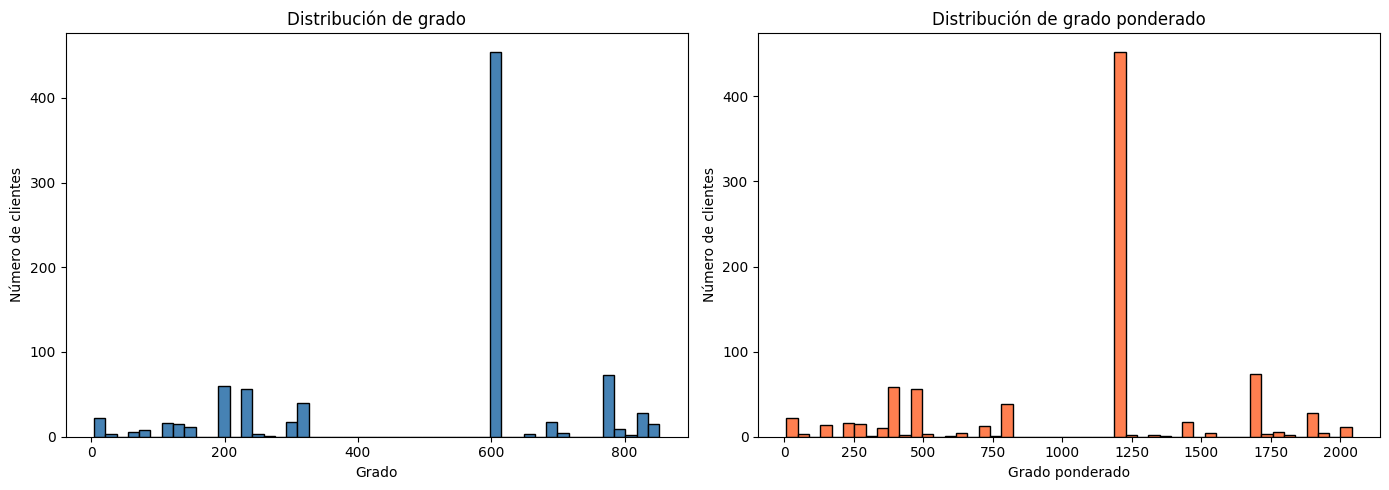


Grado según número de servicios usados:


,count,min,mean,max
num_servicios,,,,
2,633,4,477.1,604
3,130,71,611.8,781
4,83,313,568.9,830
5,16,811,836.9,842
6,1,852,852.0,852


Combinaciones de servicios más frecuentes:


,clientes,grado
combinacion,,
"SERV_1, SERV_2",451,604
"SERV_1, SERV_2, SERV_4",73,781
"SERV_1, SERV_4",58,193
"SERV_2, SERV_4",56,236
"SERV_2, SERV_4, SERV_5, SERV_6",39,316
"SERV_1, SERV_2, SERV_4, SERV_5",28,830
"SERV_1, SERV_2, SERV_5",16,689
"SERV_4, SERV_5",16,120
"SERV_2, SERV_5",15,135


Clientes con mayor grado:


,cliente,num_servicios,grado,combinacion
573,ID_3124,6,852,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6"
559,ID_982,5,842,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
59,ID_3189,5,842,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
219,ID_92,5,842,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
162,ID_10,5,842,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
522,ID_3169,5,840,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
515,ID_4909,5,840,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
312,ID_355,5,840,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
302,ID_4702,5,840,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
133,ID_3663,5,840,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"


In [12]:
# Grado y grado ponderado de cada cliente.
grados = dict(G_clientes_filtrado.degree())
grados_ponderados = dict(G_clientes_filtrado.degree(weight="weight"))
lista_grados = list(grados.values())

print("Grado mínimo:", min(lista_grados))
print("Grado máximo:", max(lista_grados))
print(f"Grado promedio: {np.mean(lista_grados):.2f}")
print(f"Mediana: {np.median(lista_grados):.0f}")
print(f"Desviación estándar: {np.std(lista_grados):.2f}")

print("\nPercentiles de grado:")
for p in [10, 25, 50, 75, 90, 95, 99]:
    print(f"  P{p}: {np.percentile(lista_grados, p):.0f}")

# Histograma de la distribución de grado.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(lista_grados, bins=50, edgecolor="black", color="steelblue")
axes[0].set_xlabel("Grado")
axes[0].set_ylabel("Número de clientes")
axes[0].set_title("Distribución de grado")

axes[1].hist(list(grados_ponderados.values()), bins=50, edgecolor="black", color="coral")
axes[1].set_xlabel("Grado ponderado")
axes[1].set_ylabel("Número de clientes")
axes[1].set_title("Distribución de grado ponderado")
plt.tight_layout()
plt.show()

# El grado de un cliente depende de la combinación de servicios que usa.
combinacion = df_limpio.groupby("PERSONA")["TIPO DE SERVICIO"].apply(lambda s: ", ".join(sorted(set(s))))
tabla_grado = pd.DataFrame({
    "combinacion": [combinacion[n] for n in G_clientes_filtrado.nodes()],
    "num_servicios": [B.degree(n) for n in G_clientes_filtrado.nodes()],
    "grado": [grados[n] for n in G_clientes_filtrado.nodes()],
})

print("\nGrado según número de servicios usados:")
display(tabla_grado.groupby("num_servicios")["grado"].agg(["count", "min", "mean", "max"]).round(1))

print("Combinaciones de servicios más frecuentes:")
display(
    tabla_grado.groupby("combinacion")["grado"].agg(clientes="count", grado="first")
    .sort_values("clientes", ascending=False).head(10)
)

print("Clientes con mayor grado:")
display(tabla_grado.assign(cliente=list(G_clientes_filtrado.nodes()))
        .sort_values("grado", ascending=False).head(10)[["cliente", "num_servicios", "grado", "combinacion"]])

INTERPRETACIÓN:
La distribución de grado no es pareja ni tiene forma de campana: está concentrada en unos pocos valores. El 52% de los clientes (451 de 863) tiene exactamente grado 604, por eso la mediana (604) queda por encima del promedio (513.3). Ese grupo corresponde a los clientes que usan la combinación SERV_1 + SERV_2. A su izquierda hay una cola de clientes con grado bajo (el mínimo es 4) y a su derecha un grupo reducido con grado alto (P90 = 781, máximo = 852).

La razón es que el grado de un cliente queda determinado por la combinación de servicios que usa: todos los clientes con la misma combinación tienen exactamente los mismos vecinos y el mismo grado. Los grados más altos corresponden a quienes combinan SERV_1 y SERV_2 con otros servicios: los 16 clientes con 5 servicios tienen grado entre 811 y 842, y el único cliente con 6 servicios (ID_3124) tiene el grado máximo, 852, conectado con el 98.8% de la red. En el otro extremo, 22 clientes tienen grado menor a 20: son los que usan solo dos servicios y uno de ellos es SERV_3 o SERV_7, los menos frecuentes.

No es una red libre de escala: no hay muchos nodos de grado bajo y unos pocos hubs, sino un bloque mayoritario muy conectado. Para el tema de centralidad esto implica que el grado identifica grupos de clientes equivalentes más que individuos, por lo que habrá muchos empates en los rankings.

### 8.4 Visualización de la red

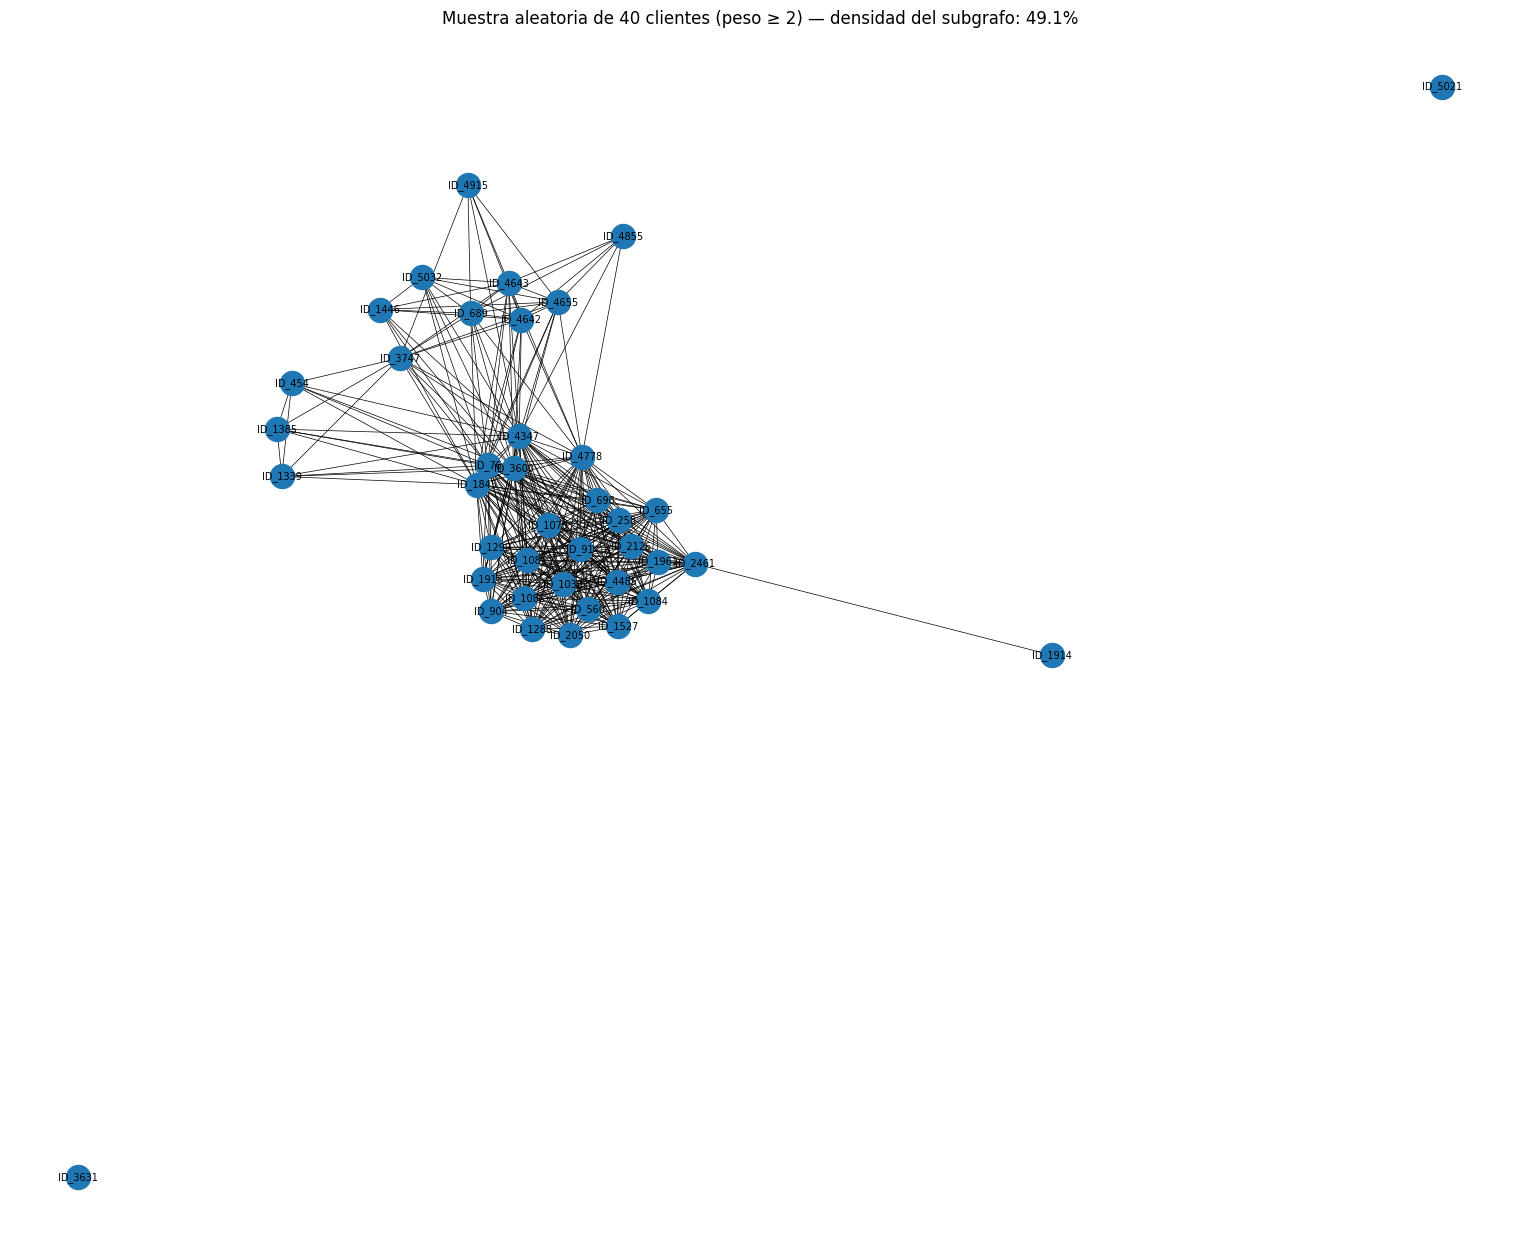

Nodos aislados dentro de la muestra: 2


In [27]:
import matplotlib.pyplot as plt
import networkx as nx
import random

random.seed(42)

# Tomar una muestra aleatoria de clientes (no los más conectados).
# Se ordenan los nodos antes de muestrear para que la muestra sea la misma en cada ejecución.
muestra = random.sample(sorted(G_clientes_filtrado.nodes()), 40)
G_visual = G_clientes_filtrado.subgraph(muestra)

plt.figure(figsize=(15, 12))
pos = nx.spring_layout(G_visual, seed=42, k=0.5)  # k más alto = nodos más separados

nx.draw(
    G_visual,
    pos,
    with_labels=True,
    node_size=300,
    font_size=7,
    width=0.5
)

densidad = nx.density(G_visual)
plt.title(f"Muestra aleatoria de 40 clientes (peso ≥ 2) — densidad del subgrafo: {densidad:.1%}")
plt.show()

print("Nodos aislados dentro de la muestra:", nx.number_of_isolates(G_visual))

INTERPRETACIÓN:
La red completa (863 nodos y 221,489 enlaces) no se puede dibujar de forma legible, por eso se grafica una muestra aleatoria de 40 clientes de `G_clientes_filtrado`. La densidad del subgrafo es 49.1%, algo menor que la de la red completa (59.5%) pero del mismo orden, así que la muestra representa razonablemente su nivel de conexión.

En el gráfico se observa un núcleo muy compacto de 25 clientes conectados casi todos entre sí; 19 de ellos usan la combinación más común, SERV_1 + SERV_2. Alrededor quedan clientes periféricos con pocas conexiones, que usan combinaciones menos frecuentes (por ejemplo SERV_1 + SERV_4). Dos clientes aparecen aislados en el dibujo (ambos usan SERV_7), pero solo porque sus vecinos no cayeron en la muestra: en la red completa no hay nodos aislados. Esta estructura de núcleo y periferia coincide con lo observado en la distribución de grado. La muestra sirve solo como ilustración: la identificación de clientes clave se hará con las métricas de centralidad calculadas sobre toda la red.

## 9. Centralidad y clientes clave

Se calculan cuatro métricas de centralidad sobre `G_clientes_filtrado` para identificar a los clientes clave:

- **Grado:** fracción de clientes con los que está conectado. Se acompaña de la **fuerza** (grado ponderado), que suma los servicios compartidos con cada vecino.
- **Intermediación (betweenness):** fracción de caminos más cortos entre otros clientes que pasan por él; identifica nodos puente.
- **Cercanía (closeness):** qué tan cerca está, en promedio, del resto de la red.
- **Autovector (eigenvector):** importancia según qué tan importantes son sus vecinos.

La intermediación y la cercanía se calculan sin pesos: el peso del enlace mide similitud (servicios compartidos), no distancia, por lo que no corresponde usarlo como longitud de camino.

### 9.1 Cálculo de las centralidades

In [14]:
# Centralidades sobre la red filtrada (la intermediación tarda alrededor de medio minuto).
metricas = ["grado", "fuerza", "intermediacion", "cercania", "autovector"]

df_centralidad = pd.DataFrame({
    "grado": pd.Series(nx.degree_centrality(G_clientes_filtrado)),
    "fuerza": pd.Series(dict(G_clientes_filtrado.degree(weight="weight"))),
    "intermediacion": pd.Series(nx.betweenness_centrality(G_clientes_filtrado, normalized=True)),
    "cercania": pd.Series(nx.closeness_centrality(G_clientes_filtrado)),
    "autovector": pd.Series(nx.eigenvector_centrality(G_clientes_filtrado, max_iter=1000)),
})

# Agregar la combinación de servicios de cada cliente para interpretar los resultados.
combinacion = df_limpio.groupby("PERSONA")["TIPO DE SERVICIO"].apply(lambda s: ", ".join(sorted(set(s))))
df_centralidad["combinacion"] = combinacion.reindex(df_centralidad.index)
df_centralidad["num_servicios"] = df_centralidad["combinacion"].str.count(",") + 1
df_centralidad.index.name = "cliente"

print("Clientes analizados:", len(df_centralidad))
display(df_centralidad[metricas].describe().round(4))

print("Clientes con intermediación igual a 0:", (df_centralidad["intermediacion"] == 0).sum())

Clientes analizados: 863


,grado,fuerza,intermediacion,cercania,autovector
count,863.0000,863.0000,863.0000,863.0000,863.0000
mean,0.5955,1064.8899,0.0005,0.7344,0.0308
std,0.2594,479.0403,0.0012,0.1259,0.0146
min,0.0046,8.0000,0.0000,0.4870,0.0001
25%,0.3515,700.0000,0.0000,0.6066,0.0128
50%,0.7007,1208.0000,0.0000,0.7696,0.0394
75%,0.7007,1208.0000,0.0002,0.7696,0.0394
max,0.9884,2042.0000,0.0121,0.9885,0.0431


Clientes con intermediación igual a 0: 633


INTERPRETACIÓN:
Se calcularon las centralidades de los 863 clientes de `G_clientes_filtrado`. La centralidad de grado promedio es 0.595 (igual a la densidad) y llega hasta 0.988: el cliente más conectado está vinculado con casi toda la red. La cercanía es alta para todos (entre 0.487 y 0.989, promedio 0.734), lo que es coherente con el diámetro de 3.

La intermediación tiene valores muy pequeños (máximo 0.0121) y vale exactamente 0 para 633 clientes, el 73% de la red. Esos 633 son los clientes que usan solo 2 servicios: para ser su vecino hay que compartir esos mismos dos servicios, así que todos sus vecinos también están conectados entre sí y ningún camino más corto necesita pasar por ellos. Solo los 230 clientes con 3 o más servicios pueden actuar como puente.

### 9.2 Ranking de clientes clave por métrica

In [15]:
# Top 10 de clientes según cada métrica.
for metrica in metricas:
    print(f"Top 10 por {metrica}:")
    display(
        df_centralidad.sort_values(metrica, ascending=False)
        .head(10)[[metrica, "num_servicios", "combinacion"]]
        .round(4)
    )

# Posición de cada cliente en cada ranking (1 = más central; los empates comparten posición).
ranking = df_centralidad[metricas].rank(ascending=False, method="min").astype(int)
print("Posición en cada ranking de los clientes destacados:")
display(ranking.loc[["ID_3124", "ID_329", "ID_2982"]])

Top 10 por grado:


,grado,num_servicios,combinacion
cliente,,,
ID_3124,0.9884,6,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6"
ID_92,0.9768,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_982,0.9768,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_3189,0.9768,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_10,0.9768,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_3167,0.9745,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_355,0.9745,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4543,0.9745,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4702,0.9745,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"


Top 10 por fuerza:


,fuerza,num_servicios,combinacion
cliente,,,
ID_3124,2042,6,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6"
ID_3167,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_37,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_3663,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4543,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4702,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_444,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_3648,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4909,2004,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"


Top 10 por intermediacion:


...

,cercania,num_servicios,combinacion
cliente,,,
ID_3124,0.9885,6,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6"
ID_92,0.9773,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_982,0.9773,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_3189,0.9773,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_10,0.9773,5,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5"
ID_3167,0.9751,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_355,0.9751,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4543,0.9751,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4702,0.9751,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"


Top 10 por autovector:


,autovector,num_servicios,combinacion
cliente,,,
ID_3124,0.0431,6,"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6"
ID_4543,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_37,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_3167,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_3663,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_4702,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_355,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_444,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"
ID_3648,0.0430,5,"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6"


Posición en cada ranking de los clientes destacados:


,grado,fuerza,intermediacion,cercania,autovector
cliente,,,,,
ID_3124,1,1,3,1,1
ID_329,45,45,1,45,45
ID_2982,54,54,2,54,54


INTERPRETACIÓN:
En grado, fuerza, cercanía y autovector el primer lugar es el mismo cliente: **ID_3124**, el único que usa 6 de los 7 servicios (grado 0.988, cercanía 0.989). Le siguen 14 clientes con 5 servicios, todos con SERV_1 y SERV_2 en su combinación: ID_3189, ID_92, ID_10 e ID_982 (SERV_1 a SERV_5) y el grupo de 10 clientes con SERV_1, SERV_2, SERV_4, SERV_5 y SERV_6. Estos son los hubs de la red: clientes que consumen casi todo el portafolio y por eso coinciden con casi todos los demás.

La intermediación da un ranking distinto. Los dos primeros son **ID_329** (SERV_1, SERV_2, SERV_4, SERV_6, SERV_7; intermediación 0.0121) e **ID_2982** (SERV_1, SERV_2, SERV_4, SERV_7; 0.0096), que en el ranking de grado ocupan recién los puestos 45 y 54. Lo que los distingue es SERV_7, el servicio con menos clientes dentro de la red filtrada (solo 16): al combinarlo con los servicios más comunes, conectan a esos pocos clientes de SERV_7 con el núcleo de la red. Son nodos puente más que hubs. ID_3124 queda tercero en intermediación, por lo que es el único cliente que destaca en todas las métricas.

Dentro de cada top hay muchos empates, porque los clientes con la misma combinación de servicios tienen exactamente la misma centralidad.

### 9.3 Comparación entre métricas

Correlación de Spearman entre métricas:


,grado,fuerza,intermediacion,cercania,autovector
grado,1.00,1.00,0.510,1.00,1.000
fuerza,1.00,1.00,0.510,1.00,1.000
intermediacion,0.51,0.51,1.000,0.51,0.509
cercania,1.00,1.00,0.510,1.00,1.000
autovector,1.00,1.00,0.509,1.00,1.000


Los 10 clientes con mayor intermediación concentran el 16.4% del total
Los 50 clientes con mayor intermediación concentran el 51.9% del total
Los 100 clientes con mayor intermediación concentran el 75.4% del total


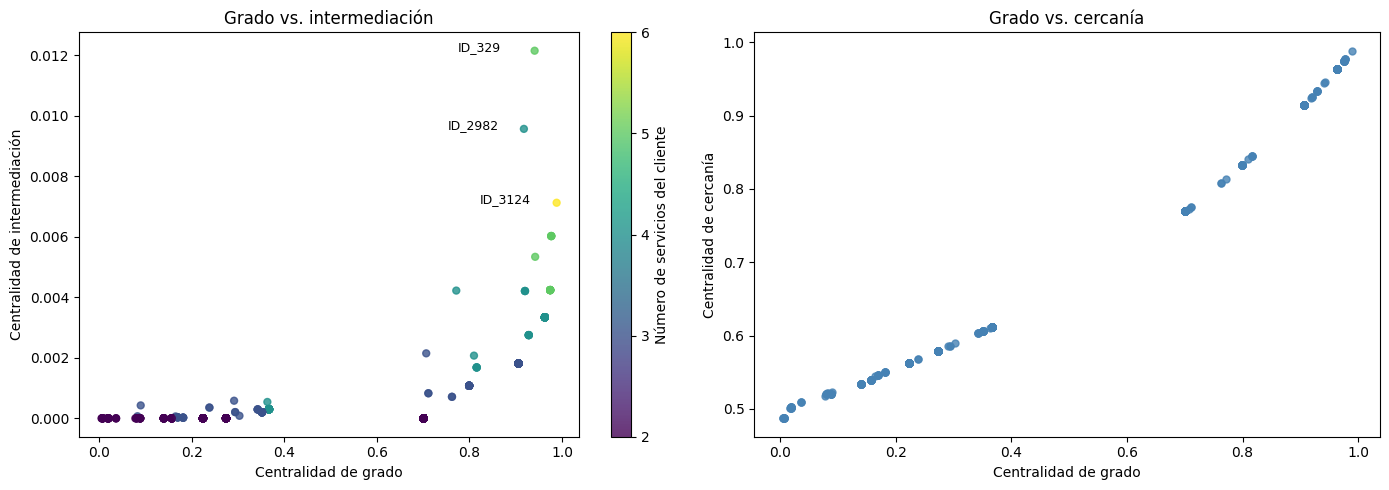

In [16]:
# Correlación de Spearman: compara el orden que cada métrica da a los clientes.
print("Correlación de Spearman entre métricas:")
display(df_centralidad[metricas].corr(method="spearman").round(3))

# Concentración de la intermediación.
inter_ordenada = df_centralidad["intermediacion"].sort_values(ascending=False)
acumulado = inter_ordenada.cumsum() / inter_ordenada.sum()
for k in [10, 50, 100]:
    print(f"Los {k} clientes con mayor intermediación concentran el {acumulado.iloc[k - 1]:.1%} del total")

# Grado frente a intermediación y frente a cercanía.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

puntos = axes[0].scatter(
    df_centralidad["grado"], df_centralidad["intermediacion"],
    c=df_centralidad["num_servicios"], cmap="viridis", s=25, alpha=0.8,
)
for cliente in ["ID_329", "ID_2982", "ID_3124"]:
    axes[0].annotate(
        cliente,
        (df_centralidad.loc[cliente, "grado"], df_centralidad.loc[cliente, "intermediacion"]),
        textcoords="offset points", xytext=(-55, 0), fontsize=9,
    )
axes[0].set_xlabel("Centralidad de grado")
axes[0].set_ylabel("Centralidad de intermediación")
axes[0].set_title("Grado vs. intermediación")
fig.colorbar(puntos, ax=axes[0], ticks=range(2, 7), label="Número de servicios del cliente")

axes[1].scatter(df_centralidad["grado"], df_centralidad["cercania"], s=25, alpha=0.8, color="steelblue")
axes[1].set_xlabel("Centralidad de grado")
axes[1].set_ylabel("Centralidad de cercanía")
axes[1].set_title("Grado vs. cercanía")

plt.tight_layout()
plt.show()

INTERPRETACIÓN:
Grado, fuerza, cercanía y autovector ordenan a los clientes prácticamente igual: la correlación de Spearman entre ellas es de 1.00 (0.9999 en el caso del autovector). En el gráfico de grado vs. cercanía los puntos caen casi sobre una misma línea. En una red tan densa y con diámetro 3, estar conectado con muchos clientes equivale a estar cerca de todos y a tener vecinos importantes, por lo que estas cuatro métricas son redundantes y basta reportar una de ellas.

La intermediación es la única que aporta información distinta: su correlación con las demás es de solo 0.51. Además está muy concentrada: los 10 clientes con mayor intermediación acumulan el 16.4% del total, los 50 primeros el 51.9% y los 100 primeros el 75.4%, mientras que 633 clientes tienen valor 0.

En el gráfico de grado vs. intermediación se ve que un grado alto no garantiza ser puente: los 451 clientes de grado 0.70 (SERV_1 + SERV_2) tienen intermediación 0, e ID_329 e ID_2982 tienen la mayor intermediación sin ser los de mayor grado. La intermediación crece con el número de servicios del cliente más que con su grado. Por eso los clientes clave se identifican con dos criterios complementarios: grado para los hubs e intermediación para los puentes.

### 9.4 Clientes clave según su perfil de servicios

In [17]:
# Centralidad promedio según el número de servicios que usa el cliente.
print("Centralidad promedio por número de servicios:")
display(
    df_centralidad.groupby("num_servicios")
    .agg(clientes=("grado", "size"), grado=("grado", "mean"),
         intermediacion=("intermediacion", "mean"), cercania=("cercania", "mean"))
    .round(4)
)

# Los clientes con la misma combinación de servicios tienen la misma centralidad,
# así que los perfiles clave se resumen por combinación.
por_combinacion = df_centralidad.groupby("combinacion").agg(
    clientes=("grado", "size"),
    grado=("grado", "mean"),
    intermediacion=("intermediacion", "mean"),
    cercania=("cercania", "mean"),
    valores_distintos=("intermediacion", "nunique"),
)
print("Combinaciones de servicios distintas:", len(por_combinacion))
print("Máximo de valores distintos de intermediación dentro de una combinación:",
      por_combinacion["valores_distintos"].max())

print("\nPerfiles con mayor grado (hubs):")
display(por_combinacion.drop(columns="valores_distintos").sort_values("grado", ascending=False).head(8).round(4))

print("Perfiles con mayor intermediación (puentes):")
display(por_combinacion.drop(columns="valores_distintos").sort_values("intermediacion", ascending=False).head(8).round(4))

# Guardar la tabla de centralidades para el Hito 2.
df_centralidad.sort_values("grado", ascending=False).to_csv("centralidades_clientes.csv")
print("Tabla guardada como: centralidades_clientes.csv")

Centralidad promedio por número de servicios:


,clientes,grado,intermediacion,cercania
num_servicios,,,,
2,633,0.5534,0.0000,0.7069
3,130,0.7097,0.0012,0.8065
4,83,0.6600,0.0019,0.7817
5,16,0.9709,0.0052,0.9719
6,1,0.9884,0.0071,0.9885


Combinaciones de servicios distintas: 47
Máximo de valores distintos de intermediación dentro de una combinación: 1

Perfiles con mayor grado (hubs):


,clientes,grado,intermediacion,cercania
combinacion,,,,
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6",1,0.9884,0.0071,0.9885
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5",4,0.9768,0.0060,0.9773
"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6",10,0.9745,0.0042,0.9751
"SERV_1, SERV_2, SERV_4, SERV_5",28,0.9629,0.0033,0.9642
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_6",1,0.9420,0.0053,0.9452
"SERV_1, SERV_2, SERV_4, SERV_6, SERV_7",1,0.9408,0.0121,0.9441
"SERV_1, SERV_2, SERV_4, SERV_6",5,0.9281,0.0028,0.9329
"SERV_1, SERV_2, SERV_3, SERV_4",3,0.9200,0.0042,0.9259


Perfiles con mayor intermediación (puentes):


,clientes,grado,intermediacion,cercania
combinacion,,,,
"SERV_1, SERV_2, SERV_4, SERV_6, SERV_7",1,0.9408,0.0121,0.9441
"SERV_1, SERV_2, SERV_4, SERV_7",1,0.9176,0.0096,0.9239
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5, SERV_6",1,0.9884,0.0071,0.9885
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_5",4,0.9768,0.0060,0.9773
"SERV_1, SERV_2, SERV_3, SERV_4, SERV_6",1,0.9420,0.0053,0.9452
"SERV_1, SERV_2, SERV_4, SERV_5, SERV_6",10,0.9745,0.0042,0.9751
"SERV_1, SERV_2, SERV_6, SERV_7",1,0.7715,0.0042,0.8140
"SERV_1, SERV_2, SERV_3, SERV_4",3,0.9200,0.0042,0.9259


Tabla guardada como: centralidades_clientes.csv


INTERPRETACIÓN:
Los 863 clientes se reparten en 47 combinaciones de servicios, y dentro de cada combinación todos tienen exactamente la misma centralidad. Por eso los clientes clave se describen mejor como perfiles de consumo que como individuos.

La centralidad aumenta con la cantidad de servicios, pero no de forma uniforme: los clientes con 5 y 6 servicios tienen grado promedio 0.97 y 0.99, mientras que los de 4 servicios (0.66) quedan por debajo de los de 3 (0.71). Lo que más pesa no es cuántos servicios usa el cliente sino si incluye SERV_1 y SERV_2 a la vez: las ocho combinaciones de mayor grado los contienen a ambos, porque son los servicios que usa la mayoría de la red.

Se distinguen dos tipos de cliente clave:

- **Hubs:** clientes con SERV_1 + SERV_2 y dos o más servicios adicionales. Son 15 clientes con grado mayor a 0.97 (ID_3124 y los 14 con cinco servicios que le siguen) y, un escalón abajo, los 28 clientes con SERV_1, SERV_2, SERV_4 y SERV_5 (grado 0.963).
- **Puentes:** clientes que combinan SERV_1 + SERV_2 con un servicio poco frecuente (SERV_7 o SERV_3). Son perfiles casi únicos, de 1 a 4 clientes cada uno, encabezados por ID_329 e ID_2982.

**Limitación:** la red filtrada solo incluye a los 863 clientes con 2 o más servicios; los 4,227 clientes de un solo servicio no tienen centralidad en este análisis. Además, el peso mínimo de 2 hace que la centralidad dependa casi por completo de la combinación de servicios, de modo que el resultado refleja la amplitud de consumo del cliente. Para el Hito 2 queda pendiente analizar cómo cambia la centralidad por año y su relación con la modalidad y la complejidad de los servicios.